In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [13]:
GROUP = "C1"
DTYPE="CMMS"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C1_10,27,"[DATA/TRAINING/C1/C1_10/IMG_6497.HEIC, DATA/TR..."
1,C1_11,26,"[DATA/TRAINING/C1/C1_11/IMG_6665.HEIC, DATA/TR..."
2,C1_12,27,"[DATA/TRAINING/C1/C1_12/IMG_6797.HEIC, DATA/TR..."
3,C1_13,27,"[DATA/TRAINING/C1/C1_13/IMG_6929.HEIC, DATA/TR..."
4,C1_14,26,"[DATA/TRAINING/C1/C1_14/IMG_7188.HEIC, DATA/TR..."
5,C1_15,28,"[DATA/TRAINING/C1/C1_15/IMG_7316.HEIC, DATA/TR..."
6,C1_16,27,"[DATA/TRAINING/C1/C1_16/IMG_7446.HEIC, DATA/TR..."


In [14]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [15]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [16]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7477.HEIC')

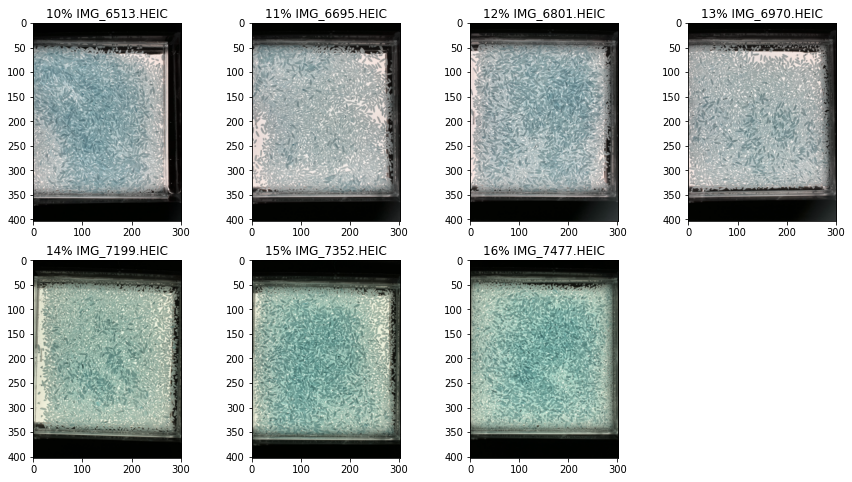

In [25]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [9]:
def color_moments(image):
    # Split the channels - h,s,v
    h, s, v = cv2.split(image)
    # Initialize the color feature
    color_feature = []
    # N = h.shape[0] * h.shape[1]
    
    # The first central moment - average
    h_mean = np.mean(h)  # np.sum(h)/float(N)
    s_mean = np.mean(s)  # np.sum(s)/float(N)
    v_mean = np.mean(v)  # np.sum(v)/float(N)
    color_feature.extend([h_mean, s_mean, v_mean])
    
    # The second central moment - standard deviation
    h_std = np.std(h)  # np.sqrt(np.mean(abs(h - h.mean())**2))
    s_std = np.std(s)  # np.sqrt(np.mean(abs(s - s.mean())**2))
    v_std = np.std(v)  # np.sqrt(np.mean(abs(v - v.mean())**2))
    color_feature.extend([h_std, s_std, v_std])
    
    # The third central moment - the third root of the skewness
    h_skewness = np.mean(abs(h - h.mean())**3)
    s_skewness = np.mean(abs(s - s.mean())**3)
    v_skewness = np.mean(abs(v - v.mean())**3)
    h_thirdMoment = h_skewness**(1./3)
    s_thirdMoment = s_skewness**(1./3)
    v_thirdMoment = v_skewness**(1./3)
    color_feature.extend([h_thirdMoment, s_thirdMoment, v_thirdMoment])
    """
    # The second central moment - standard deviation
    hist_h = cv2.calcHist([h], [0], None, [256], [0, 256])
    hist_h = cv2.normalize(hist_h, hist_h, 0, 1, cv2.NORM_MINMAX)

    hist_s = cv2.calcHist([s], [0], None, [256], [0, 256])
    hist_s = cv2.normalize(hist_s, hist_s, 0, 1, cv2.NORM_MINMAX)

    hist_v = cv2.calcHist([v], [0], None, [256], [0, 256])
    hist_v = cv2.normalize(hist_v, hist_v, 0, 1, cv2.NORM_MINMAX)

    h_skew = kurtosis(hist_h)  
    s_skew = kurtosis(hist_s) 
    v_skew = kurtosis(hist_v) 
    color_feature.extend([h_skew[0], s_skew[0], v_skew[0]])
    
    
    h_kts = kurtosis(hist_h)  
    s_kts = kurtosis(hist_s) 
    v_kts = kurtosis(hist_v) 
    color_feature.extend([h_kts[0], s_kts[0], v_kts[0]])
    
    # The second central moment - standard deviation
    h_ent = entropy(hist_h)  
    s_ent = entropy(hist_s) 
    v_ent = entropy(hist_v) 
    color_feature.extend([h_ent, s_ent, v_ent])
    """
    return color_feature

In [174]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [175]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,52.674907,35.943333,124.002222,34.126238,54.892333,69.160700,37.518295,80.208982,76.091349,3,120,90,3,IMG_6497.HEIC,10
1,57.085185,34.523704,124.253056,35.951397,50.603583,70.262335,38.511077,74.102328,77.274606,3,120,90,3,IMG_6498.HEIC,10
2,49.520000,39.430093,123.061111,32.865570,49.249504,72.750746,36.938033,71.266402,78.614309,3,120,90,3,IMG_6499.HEIC,10
3,51.305648,35.798426,123.201019,34.026098,45.938516,72.314415,37.740239,67.262360,78.297492,3,120,90,3,IMG_6500.HEIC,10
4,50.851111,37.092407,122.564907,33.214246,49.458020,72.114041,36.996658,71.619650,77.963739,3,120,90,3,IMG_6501.HEIC,10
5,54.798056,40.710833,125.166111,34.917045,53.166010,69.610693,37.812772,76.138253,77.002723,3,120,90,3,IMG_6502.HEIC,10
6,53.906944,41.697037,122.537315,34.843095,53.670427,72.568456,37.926780,74.504624,78.973584,3,120,90,3,IMG_6503.HEIC,10
7,52.515648,40.473981,123.123148,33.677882,50.196282,72.184340,37.116380,70.255705,78.805423,3,120,90,3,IMG_6504.HEIC,10
8,54.326667,42.922037,123.094444,34.868474,55.056207,72.211904,37.837436,77.374905,79.048428,3,120,90,3,IMG_6505.HEIC,10
9,56.805556,42.620185,122.843056,35.239865,55.488397,72.055950,37.755835,77.973961,78.918175,3,120,90,3,IMG_6506.HEIC,10


# Classification

In [176]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [177]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [178]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [179]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [180]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [181]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.871429,0.857143,0.864227,CMMS,C1,RF_C,3,120,90,3
1,2,0.789474,0.847619,0.785714,0.815494,CMMS,C1,RF_C,3,120,90,3
2,3,0.789474,0.726190,0.761905,0.743619,CMMS,C1,RF_C,3,120,90,3
3,4,0.736842,0.821429,0.738095,0.777535,CMMS,C1,RF_C,3,120,90,3
4,5,0.789474,0.857143,0.738095,0.793177,CMMS,C1,RF_C,3,120,90,3
5,6,0.789474,0.728571,0.761905,0.744865,CMMS,C1,RF_C,3,120,90,3
6,7,0.842105,0.857143,0.833333,0.845070,CMMS,C1,RF_C,3,120,90,3
7,8,0.842105,0.892857,0.833333,0.862069,CMMS,C1,RF_C,3,120,90,3
8,9,0.722222,0.811905,0.738095,0.773243,CMMS,C1,RF_C,3,120,90,3
9,10,0.888889,0.916667,0.904762,0.910675,CMMS,C1,RF_C,3,120,90,3


In [182]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C1,RF_C,0.803216,0.795238,0.812997,0.833095


### MLP Classifier

In [183]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [184]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [185]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.845238,0.809524,0.826996,CMMS,C1,MLP_C,3,120,90,3
1,2,0.684211,0.738095,0.714286,0.725995,CMMS,C1,MLP_C,3,120,90,3
2,3,0.684211,0.750000,0.666667,0.705882,CMMS,C1,MLP_C,3,120,90,3
3,4,0.789474,0.845238,0.785714,0.814390,CMMS,C1,MLP_C,3,120,90,3
4,5,0.736842,0.785714,0.738095,0.761161,CMMS,C1,MLP_C,3,120,90,3
5,6,0.684211,0.633333,0.666667,0.649573,CMMS,C1,MLP_C,3,120,90,3
6,7,0.894737,0.942857,0.880952,0.910854,CMMS,C1,MLP_C,3,120,90,3
7,8,0.789474,0.835714,0.785714,0.809943,CMMS,C1,MLP_C,3,120,90,3
8,9,0.888889,0.904762,0.904762,0.904762,CMMS,C1,MLP_C,3,120,90,3
9,10,0.611111,0.633333,0.619048,0.626109,CMMS,C1,MLP_C,3,120,90,3


In [186]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C1,MLP_C,0.755263,0.757143,0.773566,0.791429


### XGBoost Classifier

In [187]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [188]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.736842,0.785714,0.690476,0.735023,CMMS,C1,XGB_C,3,120,90,3
1,2,0.789474,0.859524,0.785714,0.820963,CMMS,C1,XGB_C,3,120,90,3
2,3,0.894737,0.904762,0.904762,0.904762,CMMS,C1,XGB_C,3,120,90,3
3,4,0.789474,0.833333,0.785714,0.808824,CMMS,C1,XGB_C,3,120,90,3
4,5,0.684211,0.690476,0.690476,0.690476,CMMS,C1,XGB_C,3,120,90,3
5,6,0.789474,0.797619,0.785714,0.791622,CMMS,C1,XGB_C,3,120,90,3
6,7,0.684211,0.714286,0.666667,0.689655,CMMS,C1,XGB_C,3,120,90,3
7,8,0.684211,0.795238,0.690476,0.739164,CMMS,C1,XGB_C,3,120,90,3
8,9,0.666667,0.728571,0.642857,0.683036,CMMS,C1,XGB_C,3,120,90,3
9,10,0.888889,0.904762,0.904762,0.904762,CMMS,C1,XGB_C,3,120,90,3


In [189]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C1,XGB_C,0.760819,0.754762,0.776829,0.801429


# External validation

In [190]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C1_10,5,"[DATA/TEST/C1/C1_10/IMG_6492.HEIC, DATA/TEST/C..."
1,C1_11,5,"[DATA/TEST/C1/C1_11/IMG_6655.HEIC, DATA/TEST/C..."
2,C1_12,5,"[DATA/TEST/C1/C1_12/IMG_6788.HEIC, DATA/TEST/C..."
3,C1_13,5,"[DATA/TEST/C1/C1_13/IMG_6917.HEIC, DATA/TEST/C..."
4,C1_14,5,"[DATA/TEST/C1/C1_14/IMG_7178.HEIC, DATA/TEST/C..."
5,C1_15,5,"[DATA/TEST/C1/C1_15/IMG_7304.HEIC, DATA/TEST/C..."
6,C1_16,5,"[DATA/TEST/C1/C1_16/IMG_7436.HEIC, DATA/TEST/C..."


In [191]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [192]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [193]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,44.483981,47.075648,124.469352,29.771785,53.939133,72.344638,35.068103,77.166492,78.606610,3,120,90,3,IMG_6492.HEIC,10
1,53.596759,40.498333,122.761296,34.128460,54.479726,70.922615,37.144694,78.391818,77.109629,3,120,90,3,IMG_6493.HEIC,10
2,44.491204,45.578333,125.135741,29.826776,43.895581,74.335369,35.243327,60.585642,80.833647,3,120,90,3,IMG_6494.HEIC,10
3,45.812500,45.770093,123.110556,31.149352,51.105448,72.948736,36.201619,72.866389,79.295827,3,120,90,3,IMG_6495.HEIC,10
4,50.236111,32.799074,123.699630,33.684899,38.380736,70.837538,37.634971,53.709294,77.398378,3,120,90,3,IMG_6496.HEIC,10
0,64.564074,31.640833,131.759815,32.267478,50.095930,74.036563,34.308138,66.227580,81.550061,3,120,90,3,IMG_6655.HEIC,11
1,56.398241,32.980278,131.632037,31.027196,49.301535,73.150999,33.927215,65.586537,80.950824,3,120,90,3,IMG_6657.HEIC,11
2,59.061944,33.882685,129.227500,32.971808,47.143872,75.069081,35.463589,63.238100,82.049917,3,120,90,3,IMG_6659.HEIC,11
3,61.656667,35.066852,130.880833,33.156234,49.024098,74.170167,35.221433,64.643406,81.747442,3,120,90,3,IMG_6662.HEIC,11
4,56.987130,36.387963,133.399907,32.009737,47.887602,75.139220,34.674856,63.421842,83.049874,3,120,90,3,IMG_6663.HEIC,11


In [194]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [195]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [196]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [197]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [198]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.40      0.40      0.40         5
     Class 4       0.40      0.80      0.53         5
     Class 5       0.60      0.60      0.60         5
     Class 6       0.00      0.00      0.00         5

    accuracy                           0.66        35
   macro avg       0.60      0.66      0.62        35
weighted avg       0.60      0.66      0.62        35



## MLP

In [199]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [200]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.50      0.60      0.55         5
     Class 3       0.57      0.80      0.67         5
     Class 4       0.40      0.80      0.53         5
     Class 5       0.67      0.40      0.50         5
     Class 6       0.00      0.00      0.00         5

    accuracy                           0.60        35
   macro avg       0.59      0.60      0.57        35
weighted avg       0.59      0.60      0.57        35



## XGBC

In [201]:
y_pred = modelXGBC.predict(X_test_scale) 

In [202]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.29      0.40      0.33         5
     Class 4       0.38      0.60      0.46         5
     Class 5       0.75      0.60      0.67         5
     Class 6       1.00      0.20      0.33         5

    accuracy                           0.66        35
   macro avg       0.74      0.66      0.66        35
weighted avg       0.74      0.66      0.66        35

